# 3. Evaluación y resultados
Este notebook (1) **vuelve a ejecutar un modelo entrenado** sobre el área de prueba para comprobar que reproduce las métricas guardadas, y (2) genera **todas las tablas de resultados del informe** a partir de las predicciones y métricas de cada corrida en `runs/`.

Métricas: IoU por clase, mIoU, exactitud global (OA), exactitud media por clase (mAcc) y F1, sobre el Área 2 (a la resolución submuestreada de 0,1 m y a la resolución original de 30,9 millones de puntos).

In [1]:
import json, sys, warnings
warnings.filterwarnings("ignore")
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
ROOT = Path.cwd().parent            # carpeta raíz del proyecto
sys.path.insert(0, str(ROOT / "code"))
DATA, RAW, RUNS = ROOT / "data" / "processed", ROOT / "data" / "3DAeroRelief", ROOT / "runs"
CLASES = ["Fondo", "Edif. dañada", "Edif. sin daño", "Vía", "Árbol"]
pd.set_option("display.precision", 3)
print("Proyecto:", ROOT.name)

Proyecto: Proyecto_Electiva_Danos_Estructurales


## 3.1 Ejecución del modelo entrenado (PTv3 + Utonia, semilla 0) sobre el Área 2
Se carga `runs/utonia_tiny_s0/best.pt` y se segmentan las 8 nubes de prueba (sin TTA). El resultado debe coincidir con el guardado al final del entrenamiento (diferencias en la 4.ª cifra decimal pueden deberse al no determinismo de la GPU).

In [2]:
import torch
from argparse import Namespace
from train_ptv3 import Segmentor, load_clouds, evaluate
from train import metrics
run = RUNS / "utonia_tiny_s0"
args = Namespace(**json.loads((run / "results.json").read_text())["args"]); args.eval_bs = 2
modelo = Segmentor(args.model, 5).cuda()
modelo.load_state_dict(torch.load(run / "best.pt", map_location="cuda"))
prueba = load_clouds(str(DATA), {"Area_2"})
m, cm, preds = evaluate(modelo, prueba, args, "cuda", keep_preds=True)
guardado = json.loads((run / "results.json").read_text())["test"]
pd.DataFrame({"ahora": {k: m[k] for k in ("mIoU", "OA", "mAcc", "mF1")},
              "guardado": {k: guardado[k] for k in ("mIoU", "OA", "mAcc", "mF1")}})

,ahora,guardado
mIoU,0.566,0.566
OA,0.787,0.787
mAcc,0.765,0.766
mF1,0.687,0.687


In [3]:
pd.DataFrame({"IoU ahora": m["IoU"], "IoU guardado": guardado["IoU"]}, index=CLASES)

,IoU ahora,IoU guardado
Fondo,0.684,0.683
Edif. dañada,0.658,0.659
Edif. sin daño,0.585,0.586
Vía,0.120,0.120
Árbol,0.781,0.780


## 3.2 Resultados de todas las corridas
`aggregate.py` reúne las métricas de cada corrida (`results.json`, `eval_tta_full.json`, `test_tta_fullres.json`) y calcula media ± desviación entre semillas. Es exactamente el procedimiento que genera las tablas y figuras del informe.

In [4]:
import aggregate
aggregate.main()
S = json.loads((RUNS / "summary.json").read_text())
MODELOS = ["PointNet++", "PTv3 desde cero", "PTv3 + Sonata", "PTv3 + Utonia"]
ms = lambda o: f"{o['mean']:.3f} ± {o['std']:.3f}" if o["n"] > 1 else f"{o['mean']:.3f}"
tabla = pd.DataFrame([{"Modelo": m, "Semillas": len(S[m]["runs"]),
    "mIoU vóxel": ms(S[m]["vox"]["mIoU"]), "mIoU vóxel TTA": ms(S[m]["vox_tta"]["mIoU"]),
    "mIoU original": ms(S[m]["full_tta"]["mIoU"]), "OA original": ms(S[m]["full_tta"]["OA"]),
    "mAcc original": ms(S[m]["full_tta"]["mAcc"]), "IoU dañada": ms(S[m]["full_tta"]["IoU"][1])} for m in MODELOS])
print("Tabla principal del informe (Área 2):"); tabla

PointNet++       semillas=3 val=0.529 | vox: mIoU 0.461±0.023 | vox_tta: mIoU 0.461±0.023 | full_tta: mIoU 0.436±0.033
PTv3 desde cero  semillas=1 val=0.530 | vox: mIoU 0.449±0.000 | vox_tta: mIoU 0.469±0.000 | full_tta: mIoU 0.447±0.000
PTv3 + Sonata    semillas=3 val=0.552 | vox: mIoU 0.469±0.064 | vox_tta: mIoU 0.474±0.053 | full_tta: mIoU 0.505±0.045
PTv3 + Utonia    semillas=3 val=0.554 | vox: mIoU 0.523±0.040 | vox_tta: mIoU 0.514±0.049 | full_tta: mIoU 0.545±0.030
mejor por validación: PTv3 + Utonia | mejor en prueba: PTv3 + Utonia
Tabla principal del informe (Área 2):


,Modelo,Semillas,mIoU vóxel,mIoU vóxel TTA,mIoU original,OA original,mAcc original,IoU dañada
0,PointNet++,3,0.461 ± 0.023,0.461 ± 0.023,0.436 ± 0.033,0.752 ± 0.055,0.606 ± 0.046,0.595 ± 0.092
1,PTv3 desde cero,1,0.449,0.469,0.447,0.778,0.637,0.731
2,PTv3 + Sonata,3,0.469 ± 0.064,0.474 ± 0.053,0.505 ± 0.045,0.824 ± 0.049,0.691 ± 0.018,0.745 ± 0.071
3,PTv3 + Utonia,3,0.523 ± 0.040,0.514 ± 0.049,0.545 ± 0.030,0.840 ± 0.028,0.737 ± 0.020,0.749 ± 0.054


### IoU por clase (resolución original, con TTA, media de semillas)

In [5]:
pd.DataFrame({m: [S[m]["full_tta"]["IoU"][c]["mean"] for c in range(5)] + [S[m]["full_tta"]["mIoU"]["mean"]]
              for m in MODELOS}, index=CLASES + ["mIoU"]).T.round(3)

,Fondo,Edif. dañada,Edif. sin daño,Vía,Árbol,mIoU
PointNet++,0.799,0.595,0.133,0.044,0.608,0.436
PTv3 desde cero,0.716,0.731,0.172,0.042,0.572,0.447
PTv3 + Sonata,0.799,0.745,0.269,0.068,0.643,0.505
PTv3 + Utonia,0.807,0.749,0.310,0.222,0.639,0.545


### Variabilidad entre semillas (mIoU de validación y de prueba)

In [6]:
pd.DataFrame([{"Modelo": m, "mIoU validación (s0/s1/s2)": " / ".join(f"{v:.3f}" for v in S[m]["best_val"]["values"]),
               "mIoU prueba (s0/s1/s2)": " / ".join(f"{v:.3f}" for v in S[m]["full_tta"]["mIoU"]["values"])}
              for m in MODELOS if len(S[m]["runs"]) > 1])

,Modelo,mIoU validación (s0/s1/s2),mIoU prueba (s0/s1/s2)
0,PointNet++,0.539 / 0.532 / 0.516,0.469 / 0.434 / 0.403
1,PTv3 + Sonata,0.552 / 0.553 / 0.552,0.528 / 0.453 / 0.534
2,PTv3 + Utonia,0.532 / 0.554 / 0.578,0.577 / 0.517 / 0.542


## 3.3 Comparación con el benchmark publicado (Le et al., 2026)

In [7]:
bench = {"PTv1": ([0.385, 0.511, 0.154, 0.300, 0.191], 0.308, 0.461), "PTv2": ([0.501, 0.002, 0.253, 0.486, 0.037], 0.256, 0.394),
         "PTv3": ([0.773, 0.761, 0.311, 0.047, 0.400], 0.458, 0.551), "FPT": ([0.41, 0.14, 0.03, 0.00, 0.00], 0.11, 0.22),
         "OA-CNNs": ([0.228, 0.582, 0.196, 0.000, 0.296], 0.260, 0.440)}
filas = [dict(Método=k + " (artículo)", **dict(zip(CLASES, iou)), mIoU=mi, mAcc=ma) for k, (iou, mi, ma) in bench.items()]
filas += [dict(Método=m + " (este trabajo)", **{c: S[m]["full_tta"]["IoU"][i]["mean"] for i, c in enumerate(CLASES)},
               mIoU=S[m]["full_tta"]["mIoU"]["mean"], mAcc=S[m]["full_tta"]["mAcc"]["mean"]) for m in MODELOS]
pd.DataFrame(filas).round(3)

,Método,Fondo,Edif. dañada,Edif. sin daño,Vía,Árbol,mIoU,mAcc
0,PTv1 (artículo),0.385,0.511,0.154,0.300,0.191,0.308,0.461
1,PTv2 (artículo),0.501,0.002,0.253,0.486,0.037,0.256,0.394
2,PTv3 (artículo),0.773,0.761,0.311,0.047,0.400,0.458,0.551
3,FPT (artículo),0.410,0.140,0.030,0.000,0.000,0.110,0.220
4,OA-CNNs (artículo),0.228,0.582,0.196,0.000,0.296,0.260,0.440
5,PointNet++ (este trabajo),0.799,0.595,0.133,0.044,0.608,0.436,0.606
6,PTv3 desde cero (este trabajo),0.716,0.731,0.172,0.042,0.572,0.447,0.637
7,PTv3 + Sonata (este trabajo),0.799,0.745,0.269,0.068,0.643,0.505,0.691
8,PTv3 + Utonia (este trabajo),0.807,0.749,0.310,0.222,0.639,0.545,0.737


## 3.4 Exactitud por nube (semilla 0): PointNet++ vs. PTv3 + Utonia

In [8]:
P1 = np.load(RUNS / "pn2" / "eval_tta_full_preds.npz"); P2 = np.load(RUNS / "utonia_tiny_s0" / "test_tta_preds.npz")
filas = []
for k in sorted(P1.files):
    lab = np.load(DATA / f"{k}.npz")["label"]
    a, b = (P1[k] == lab).mean(), (P2[k] == lab).mean()
    filas.append(dict(Nube=k.replace("Area_2_", ""), **{"PointNet++": a, "PTv3 + Utonia": b, "Diferencia": b - a}))
pd.DataFrame(filas).round(2)

,Nube,PointNet++,PTv3 + Utonia,Diferencia
0,pp1,0.72,0.67,-0.05
1,pp2,0.66,0.75,0.09
2,pp3,0.78,0.82,0.04
3,pp4,0.82,0.80,-0.02
4,pp5,0.61,0.53,-0.08
5,pp6,0.60,0.92,0.33
6,pp7,0.79,0.93,0.15
7,pp8,0.88,0.96,0.09


## 3.5 Figuras del informe

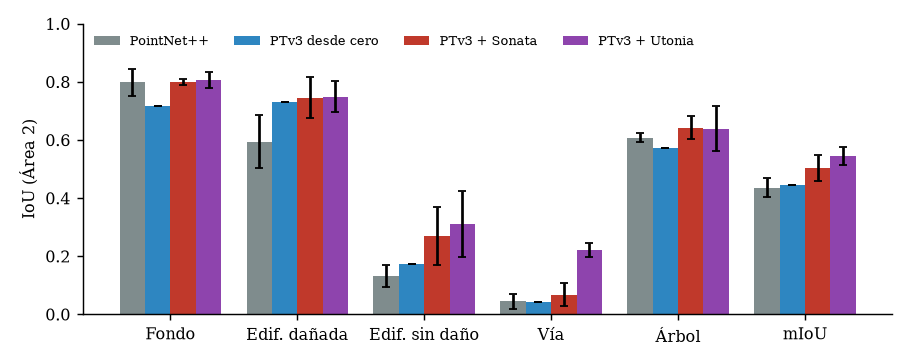

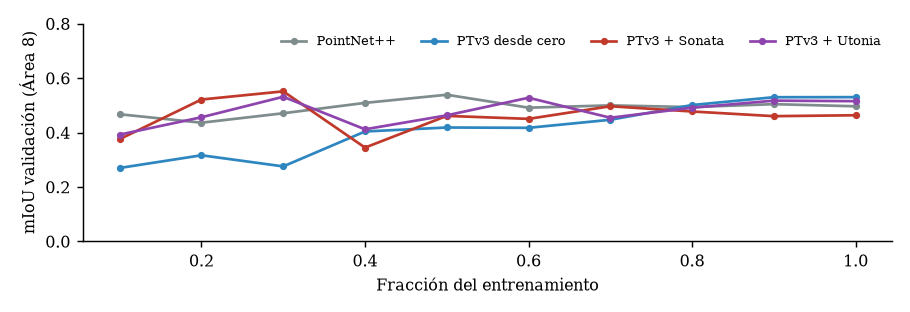

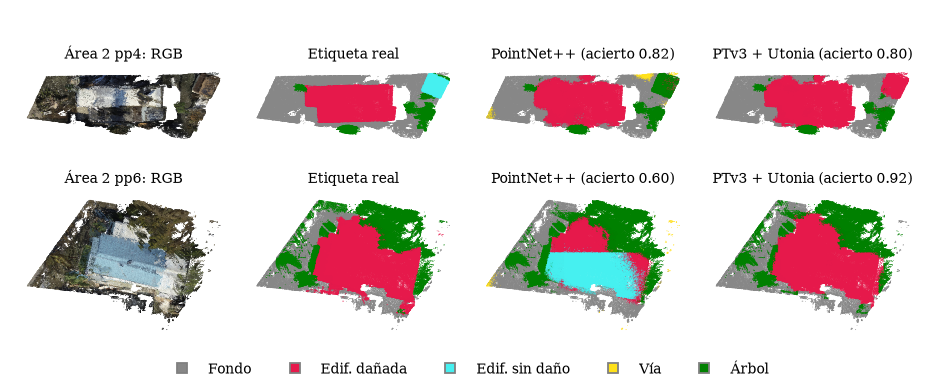

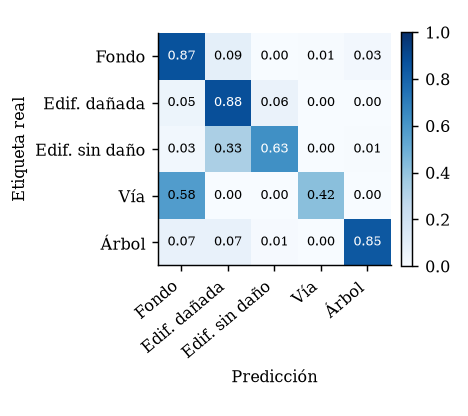

In [9]:
from IPython.display import Image, display
for f in ["iou_modelos.png", "curvas_val.png", "cualitativo_final.png", "confusion_mejor.png"]:
    display(Image(filename=str(ROOT / "entrega_final" / "figs" / f)))